# CS 521 HW4, Problem 3: PPO on CartPole

Open this notebook in Google Colab. The CPU runtime is sufficient: a GPU does not make this notebook faster.

The notebook has a complete implementation of PPO for the CartPole-v1 environment.
In part (a) of Problem 3, you run it and examine two of its parts.
In Bonus Research Question 2, you change the algorithm to improve learning.
Do not change the environment, the training budget (`total_steps`) or the evaluation.

**Environment.** CartPole-v1 gives a reward of +1 for each step. An episode ends when the pole falls
(*termination*) or after 500 steps (*truncation*, a time limit). Thus the maximum return is 500.

In [1]:
# !pip install gymnasium   # Colab has gymnasium. Remove the comment if the import fails.
import copy
import time

import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn
from torch.distributions import Categorical

torch.set_num_threads(1)

CONFIG = dict(
    total_steps=200_000,   # training budget (environment steps). Do not change.
    num_envs=4,            # parallel environments
    num_steps=128,         # steps per environment for each rollout
    lr=2.5e-4,
    anneal_lr=True,        # decrease the learning rate linearly to 0
    gamma=0.99,
    gae_lambda=0.95,
    num_minibatches=4,
    update_epochs=4,
    clip_coef=0.2,
    ent_coef=0.01,
    vf_coef=0.5,
    max_grad_norm=0.5,
    norm_adv=True,         # normalize the advantages in each minibatch
)
SEEDS = [0, 1, 2, 3, 4]

# Environments

`Envs` runs `num_envs` copies of CartPole. When an episode ends, `step` resets that copy automatically.
For each copy, `step` returns:

* `obs`: the next observation. If the episode ended, this is the first observation of the new episode.
* `reward`, `terminated`, `truncated`.
* `final_obs`: the last observation of the episode that ended (`None` if the episode did not end).

`step` also records the return of each finished episode in `self.episodes` as `(global_step, return)`.

In [2]:
class Envs:
    def __init__(self, n, seed):
        self.envs = [gym.make("CartPole-v1") for _ in range(n)]
        self.obs = np.stack([e.reset(seed=seed + i)[0] for i, e in enumerate(self.envs)])
        for i, e in enumerate(self.envs):
            e.action_space.seed(seed + i)
        self.ep_return = np.zeros(n)
        self.global_step = 0
        self.episodes = []

    def step(self, actions):
        rewards, terms, truncs, final_obs = [], [], [], []
        for i, (e, a) in enumerate(zip(self.envs, actions)):
            o, r, term, trunc, _ = e.step(int(a))
            self.ep_return[i] += r
            fo = None
            if term or trunc:
                fo = o
                self.episodes.append((self.global_step + i + 1, self.ep_return[i]))
                self.ep_return[i] = 0
                o, _ = e.reset()
            self.obs[i] = o
            rewards.append(r); terms.append(term); truncs.append(trunc); final_obs.append(fo)
        self.global_step += len(self.envs)
        return self.obs.copy(), np.array(rewards), np.array(terms), np.array(truncs), final_obs

# Agent

The agent has two separate networks with 2 hidden layers of 64 neurons: the actor (policy) and the critic (value).

In [3]:
def layer_init(layer, std=np.sqrt(2), bias=0.0):
    nn.init.orthogonal_(layer.weight, std)
    nn.init.constant_(layer.bias, bias)
    return layer

class Agent(nn.Module):
    def __init__(self, obs_dim=4, n_actions=2):
        super().__init__()
        self.critic = nn.Sequential(
            layer_init(nn.Linear(obs_dim, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 1), std=1.0))
        self.actor = nn.Sequential(
            layer_init(nn.Linear(obs_dim, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, n_actions), std=0.01))

    def get_value(self, x):
        return self.critic(x).squeeze(-1)

    def get_action_and_value(self, x, action=None):
        dist = Categorical(logits=self.actor(x))
        if action is None:
            action = dist.sample()
        return action, dist.log_prob(action), dist.entropy(), self.get_value(x)

# PPO

`compute_gae` calculates the advantages with generalized advantage estimation (GAE).
`ppo_update` does `update_epochs` passes over the rollout with the clipped surrogate objective.
`train_ppo(seed, cfg)` trains one agent and returns the agent and the list of `(global_step, return)` of the
training episodes.

In [4]:
def compute_gae(rewards, values, dones, next_value, next_done, gamma, lam):
    # rewards, values, dones: (num_steps, num_envs). dones[t] = 1 if the episode ended at step t - 1,
    # thus obs[t] is the first observation of a new episode.
    T = len(rewards)
    adv = torch.zeros_like(rewards)
    last = 0
    for t in reversed(range(T)):
        not_done = 1.0 - (next_done if t == T - 1 else dones[t + 1])
        nv = next_value if t == T - 1 else values[t + 1]
        delta = rewards[t] + gamma * nv * not_done - values[t]
        last = delta + gamma * lam * not_done * last
        adv[t] = last
    return adv, adv + values


def ppo_update(agent, opt, b, cfg):
    n = len(b["obs"])
    mb_size = n // cfg["num_minibatches"]
    stats = []
    for _ in range(cfg["update_epochs"]):
        idx = torch.randperm(n)
        for start in range(0, n, mb_size):
            mb = idx[start:start + mb_size]
            _, logp, ent, v = agent.get_action_and_value(b["obs"][mb], b["actions"][mb])
            ratio = (logp - b["logp"][mb]).exp()
            adv = b["adv"][mb]
            if cfg["norm_adv"]:
                adv = (adv - adv.mean()) / (adv.std() + 1e-8)
            pg_loss = torch.max(-adv * ratio,
                                -adv * ratio.clamp(1 - cfg["clip_coef"], 1 + cfg["clip_coef"])).mean()
            v_loss = 0.5 * ((v - b["returns"][mb]) ** 2).mean()
            loss = pg_loss - cfg["ent_coef"] * ent.mean() + cfg["vf_coef"] * v_loss
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(agent.parameters(), cfg["max_grad_norm"])
            opt.step()
            stats.append(((ratio - 1).abs() > cfg["clip_coef"]).float().mean().item())
    return {"clip_frac": float(np.mean(stats))}


def train_ppo(seed, cfg=None, verbose=False):
    cfg = {**CONFIG, **(cfg or {})}
    torch.manual_seed(seed)
    np.random.seed(seed)
    envs = Envs(cfg["num_envs"], seed)
    agent = Agent()
    opt = torch.optim.Adam(agent.parameters(), lr=cfg["lr"], eps=1e-5)
    N, T = cfg["num_envs"], cfg["num_steps"]
    n_updates = cfg["total_steps"] // (N * T)
    obs = torch.zeros(T, N, 4); actions = torch.zeros(T, N, dtype=torch.long)
    logps = torch.zeros(T, N); rewards = torch.zeros(T, N); dones = torch.zeros(T, N); values = torch.zeros(T, N)
    next_obs = torch.tensor(envs.obs, dtype=torch.float32)
    next_done = torch.zeros(N)
    start = time.time()
    for update in range(n_updates):
        if cfg["anneal_lr"]:
            opt.param_groups[0]["lr"] = cfg["lr"] * (1 - update / n_updates)
        for t in range(T):
            obs[t], dones[t] = next_obs, next_done
            with torch.no_grad():
                a, logp, _, v = agent.get_action_and_value(next_obs)
            actions[t], logps[t], values[t] = a, logp, v
            o, r, term, trunc, _ = envs.step(a.numpy())
            rewards[t] = torch.tensor(r, dtype=torch.float32)
            next_obs = torch.tensor(o, dtype=torch.float32)
            next_done = torch.tensor(term | trunc, dtype=torch.float32)
        with torch.no_grad():
            adv, returns = compute_gae(rewards, values, dones, agent.get_value(next_obs), next_done,
                                       cfg["gamma"], cfg["gae_lambda"])
        b = {"obs": obs.reshape(-1, 4), "actions": actions.reshape(-1), "logp": logps.reshape(-1),
             "adv": adv.reshape(-1), "returns": returns.reshape(-1)}
        stats = ppo_update(agent, opt, b, cfg)
        if verbose and (update + 1) % 20 == 0:
            recent = [r for _, r in envs.episodes[-10:]]
            print(f"step {envs.global_step:6d}  mean return (last 10) {np.mean(recent):6.1f}  "
                  f"clip frac {stats['clip_frac']:.3f}")
    return agent, envs.episodes, time.time() - start

# Evaluation

`evaluate_policy` runs the greedy policy (the action with the highest probability) for 20 episodes with fixed seeds.
`summarize(runs)` gives these metrics for a list of runs (one run for each seed):

* `auc`: the mean of the learning curve over the training budget. The learning curve is the mean return of the last
  10 training episodes, at 100 equally spaced steps. A higher value means faster learning.
* `steps_to_475`: the first step where the mean return of the last 10 training episodes is at least 475.
  If a run does not get there, we use `total_steps`.
* `final`: the return of the greedy policy at the end of training.

`plot_curves` plots the mean learning curve over the seeds. Use these functions for all the numbers in your report.

In [5]:
@torch.no_grad()
def evaluate_policy(agent, episodes=20, seed=10_000):
    env = gym.make("CartPole-v1")
    total = 0.0
    for k in range(episodes):
        o, _ = env.reset(seed=seed + k)
        done = False
        while not done:
            a = agent.actor(torch.tensor(o, dtype=torch.float32)).argmax().item()
            o, r, term, trunc, _ = env.step(a)
            total += r
            done = term or trunc
    return total / episodes


def learning_curve(episodes, total_steps=CONFIG["total_steps"], points=100, window=10):
    steps = np.array([s for s, _ in episodes])
    rets = np.array([r for _, r in episodes])
    grid = np.linspace(total_steps / points, total_steps, points)
    curve = []
    for g in grid:
        r = rets[steps <= g][-window:]
        curve.append(r.mean() if len(r) else 0.0)
    return grid, np.array(curve)


def steps_to(episodes, target=475, window=10, total_steps=CONFIG["total_steps"]):
    rets = [r for _, r in episodes]
    for k in range(window, len(episodes) + 1):
        if np.mean(rets[k - window:k]) >= target:
            return episodes[k - 1][0]
    return total_steps


def run_seeds(cfg=None, seeds=SEEDS, train_fn=None, verbose=True):
    train_fn = train_fn or train_ppo
    runs = []
    for s in seeds:
        agent, episodes, sec = train_fn(s, cfg)
        runs.append({"seed": s, "episodes": episodes, "time": sec, "final": evaluate_policy(agent)})
        if verbose:
            print(f"seed {s}: auc {learning_curve(episodes)[1].mean():6.1f}  steps_to_475 {steps_to(episodes):6d}  "
                  f"final {runs[-1]['final']:6.1f}  time {sec:5.1f} s")
    return runs


def summarize(runs, name=""):
    auc = [learning_curve(r["episodes"])[1].mean() for r in runs]
    st = [steps_to(r["episodes"]) for r in runs]
    fin = [r["final"] for r in runs]
    res = {"name": name, "auc": np.mean(auc), "auc_std": np.std(auc), "steps_to_475": np.mean(st),
           "solved": sum(s < CONFIG["total_steps"] for s in st), "final": np.mean(fin),
           "final_std": np.std(fin), "time": np.mean([r["time"] for r in runs])}
    print(f"{name:<24} auc {res['auc']:6.1f} +- {res['auc_std']:5.1f}  steps_to_475 {res['steps_to_475']:8.0f} "
          f"({res['solved']}/{len(runs)} runs)  final {res['final']:6.1f} +- {res['final_std']:5.1f}  "
          f"time {res['time']:5.1f} s")
    return res


def plot_curves(named_runs):
    import matplotlib.pyplot as plt
    for name, runs in named_runs.items():
        curves = np.stack([learning_curve(r["episodes"])[1] for r in runs])
        grid = learning_curve(runs[0]["episodes"])[0]
        m, s = curves.mean(0), curves.std(0)
        plt.plot(grid, m, label=name)
        plt.fill_between(grid, m - s, m + s, alpha=0.2)
    plt.xlabel("environment steps"); plt.ylabel("mean return (last 10 episodes)"); plt.legend(); plt.show()

# (a) Run PPO

Train PPO with the default configuration for the 5 seeds. Then train two changed versions:

* Without clipping: `{"clip_coef": 1e9}`.
* Without GAE (Monte Carlo advantages): `{"gae_lambda": 1.0}`.

seed 0: auc  312.3  steps_to_475 147774  final  500.0  time  70.2 s
seed 1: auc  244.2  steps_to_475  95166  final  294.8  time  68.7 s
seed 2: auc  329.1  steps_to_475  76370  final  495.1  time  69.2 s
seed 3: auc  340.3  steps_to_475  69435  final  453.4  time  67.6 s
seed 4: auc  361.6  steps_to_475  99675  final  500.0  time  68.3 s
seed 0: auc  252.0  steps_to_475  68297  final  170.9  time  67.6 s
seed 1: auc  379.3  steps_to_475  79270  final  500.0  time  69.8 s
seed 2: auc  311.2  steps_to_475  65676  final  475.6  time  68.4 s
seed 3: auc  361.7  steps_to_475  57064  final  500.0  time  68.2 s
seed 4: auc  364.4  steps_to_475  54662  final  500.0  time  69.0 s
seed 0: auc  287.8  steps_to_475 165270  final  500.0  time  69.4 s
seed 1: auc  300.6  steps_to_475 113729  final  495.8  time  68.7 s
seed 2: auc  344.6  steps_to_475  85506  final  500.0  time  68.4 s
seed 3: auc  337.0  steps_to_475  93652  final  495.9  time  68.1 s
seed 4: auc  328.9  steps_to_475  73589  final  

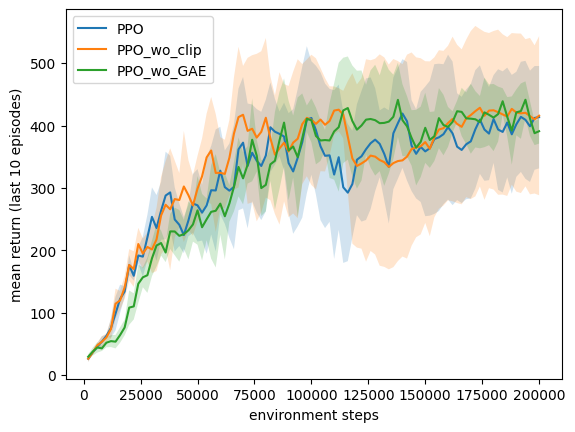

In [6]:
cfg_wo_clip = {"clip_coef": 1e9}
cfg_wo_gae = {"gae_lambda": 1.0}
all_runs = {"PPO": run_seeds(), "PPO_wo_clip": run_seeds(cfg=cfg_wo_clip), "PPO_wo_GAE": run_seeds(cfg=cfg_wo_gae)}
results = {name: summarize(runs, name) for name, runs in all_runs.items()}
plot_curves(all_runs)

In [7]:
print(results)

{'PPO': {'name': 'PPO', 'auc': np.float64(317.51120000000003), 'auc_std': np.float64(39.98945237634541), 'steps_to_475': np.float64(97684.0), 'solved': 5, 'final': np.float64(448.65), 'final_std': np.float64(78.89633705058809), 'time': np.float64(68.79636645317078)}, 'PPO_wo_clip': {'name': 'PPO_wo_clip', 'auc': np.float64(333.735), 'auc_std': np.float64(46.86728682994144), 'steps_to_475': np.float64(64993.8), 'solved': 5, 'final': np.float64(429.28999999999996), 'final_std': np.float64(129.54157016185962), 'time': np.float64(68.59961433410645)}, 'PPO_wo_GAE': {'name': 'PPO_wo_GAE', 'auc': np.float64(319.773), 'auc_std': np.float64(21.856599332924606), 'steps_to_475': np.float64(106349.2), 'solved': 5, 'final': np.float64(498.32), 'final_std': np.float64(2.057814374524577), 'time': np.float64(68.41224703788757)}}


## (a) Answers

PPO with the default settings, PPO without clipping (`clip_coef = 1e9`) and PPO without GAE (`gae_lambda = 1.0`), each for the 5 seeds 0–4 with 200,000 environment steps. Mean ± std over the seeds, from `summarize`. The columns auc and steps_to_475 are computed from the learning curve, which is the return of the sampled policy during training (mean of the last 10 episodes). The column final is the return of the greedy policy (always the action with the highest probability), averaged over 20 evaluation episodes at the end of training. The learning curves are in the plot above (mean over the seeds, band = ±1 std).

| Version | auc | steps_to_475 | final (greedy) |
|---|---|---|---|
| PPO | 317.5 ± 40.0 | 97,684 | 448.6 ± 78.9 |
| PPO without clipping | 333.7 ± 46.9 | 64,994 | 429.3 ± 129.5 |
| PPO without GAE | 319.8 ± 21.9 | 106,349 | 498.3 ± 2.1 |

Per-seed `steps_to_475` (seeds 0–4): PPO 147,774 / 95,166 / 76,370 / 69,435 / 99,675. Without clipping 68,297 / 79,270 / 65,676 / 57,064 / 54,662. Without GAE 165,270 / 113,729 / 85,506 / 93,652 / 73,589.
Per-seed greedy `final`: PPO 500.0 / 294.8 / 495.1 / 453.4 / 500.0. Without clipping 170.9 / 500.0 / 475.6 / 500.0 / 500.0. Without GAE 500.0 / 495.8 / 500.0 / 495.9 / 500.0.

**(i) Clipping.**

* Without clipping, 475 is reached faster: 64,994 vs 97,684 steps, and faster in each of the 5 seeds. The auc difference (333.7 vs 317.5) is below the std over seeds (40–47).
* The final policy is less reliable without clipping: std of `final` 129.5 vs 78.9, and one seed ends at 170.9.
* **Why:** Clipping removes the gradient of a sample once its probability ratio $\pi_{new}(a|s)/\pi_{old}(a|s)$ has moved by more than 0.2 in the direction that the objective wants: above 1.2 for an action with a positive advantage (its probability was already increased) and below 0.8 for an action with a negative advantage (already decreased). This limits how far the policy moves over the 4 passes (update epochs) that PPO makes over each rollout, so learning is slower and safer. Without clipping, each rollout moves the policy more. The runs do not diverge since the gradient-norm clip (0.5) and the small, decaying learning rate remain.

**(ii) GAE.** Why the two versions differ, in terms of the bias and the variance of the advantage estimates:

* With GAE ($\lambda = 0.95$), the critic partly replaces the later rewards. The advantage has a lower variance (fewer random rewards in the sum) and a higher bias (the critic can be wrong, especially early in training).
* Without GAE ($\lambda = 1$), the advantage is the discounted reward collected until the end of the episode (or of the rollout) minus the critic's value $V(s_t)$. It has almost no bias from the critic and a high variance, since it sums many random rewards.
* Results: GAE is slightly faster to 475 (97.7k vs 106.3k steps, faster in 4 of 5 seeds) and has the same auc (317.5 vs 319.8). The version without GAE has the smaller std of auc (21.9 vs 40.0) and the better final policy (498.3 ± 2.1 vs 448.6 ± 78.9).

**(iii) Does PPO keep the maximum return?** No, not consistently.

* All 5 seeds of every version reach a mean return of 475, but the mean curves do not stay near 500. They rise to about 400 at 70k–100k steps, then stay between about 300 and 440 until 200k. PPO dips to about 300 near 115k steps, and PPO without clipping to about 340 at 120k–150k. The curves end at about 410 (PPO), 415 (no clipping) and 390 (no GAE), with bands of about ±100.
* The greedy policy at the end: 2 of 5 PPO seeds (294.8, 453.4) and 1 of 5 seeds without clipping (170.9) end below 475. All seeds without GAE end at 495 or higher.


# Bonus Research Question 2: your method

Write your method as a copy of `train_ppo` (and of the other functions that you change).
Use `run_seeds(train_fn=my_train_ppo)` and `summarize` for the results.

## (i) Idea: reward normalization

In CartPole the reward is 1 per step and an episode lasts up to 500 steps. With $\gamma = 0.99$, the discounted return of a state is up to $\sum_{t<500} 0.99^t = (1-0.99^{500})/(1-0.99) \approx 99.3$, which is about $1/(1-\gamma) = 100$. The critic has to predict returns of this size, so its loss and gradient are much larger than those of the actor.

The gradient norm is the length of the gradient vector of the parameters of a network, so it measures how large the gradient is. The gradient norms before clipping in a run with seed 0 (printed every 20 updates, see the gradient norm cell below) are 6.3 to 44.2 for the critic and 0.13 to 0.39 for the actor. `ppo_update` clips the combined gradient of the actor and the critic to norm 0.5. The norm of the combined gradient is dominated by the critic when the critic gradient is much larger, and the clip then also shrinks the actor gradient by a factor that the critic dominates.

**Method.** Divide each reward by the running standard deviation of the discounted return. A return is a sum of rewards, so the returns are divided by $\sigma$ as well, and the critic's errors and gradient become smaller. The rest of PPO is unchanged. **This is the reward scaling of Engstrom et al. [1].** I expect the critic gradient to become of the same order as the actor gradient, so that the critic no longer dominates the combined gradient and the clip does not shrink the actor update by a factor that the critic dominates.

**References**

* [1] L. Engstrom, A. Ilyas, S. Santurkar, D. Tsipras, F. Janoos, L. Rudolph, A. Madry. *Implementation Matters in Deep Policy Gradients: A Case Study on PPO and TRPO.* ICLR 2020.


## (ii) Implementation

In [8]:
# NEW (only for the analysis, does not change training): size of the gradient of a network
def grad_norm(net):
    return torch.sqrt(sum((p.grad ** 2).sum() for p in net.parameters())).item()


# Same as ppo_update. The only difference: it also records the gradient norms of the actor and the critic.
def my_ppo_update(agent, opt, b, cfg, options):
    n = len(b["obs"])
    mb_size = n // cfg["num_minibatches"]
    stats, gn = [], []   # NEW: gn stores the gradient norms
    for _ in range(cfg["update_epochs"]):
        idx = torch.randperm(n)
        for start in range(0, n, mb_size):
            mb = idx[start:start + mb_size]
            _, logp, ent, v = agent.get_action_and_value(b["obs"][mb], b["actions"][mb])
            ratio = (logp - b["logp"][mb]).exp()
            adv = b["adv"][mb]
            if cfg["norm_adv"]:
                adv = (adv - adv.mean()) / (adv.std() + 1e-8)
            pg_loss = torch.max(-adv * ratio, -adv * ratio.clamp(1 - cfg["clip_coef"], 1 + cfg["clip_coef"])).mean()
            v_loss = 0.5 * ((v - b["returns"][mb]) ** 2).mean()
            loss = pg_loss - cfg["ent_coef"] * ent.mean() + cfg["vf_coef"] * v_loss
            opt.zero_grad()
            loss.backward()
            gn.append((grad_norm(agent.actor), grad_norm(agent.critic)))   # NEW: gradient norms before clipping (logging only)
            nn.utils.clip_grad_norm_(agent.parameters(), cfg["max_grad_norm"])
            opt.step()
            stats.append(((ratio - 1).abs() > cfg["clip_coef"]).float().mean().item())
    # NEW: the two gradient norms are returned in addition to clip_frac
    return {"clip_frac": float(np.mean(stats)), "actor_gn": float(np.mean([g[0] for g in gn])), "critic_gn": float(np.mean([g[1] for g in gn]))}


# Same as train_ppo. The only change that affects training is the reward normalization (marked NEW below).
def my_train_ppo(seed, cfg=None, verbose=False, options=None):
    options = {"reward_norm": True, **(options or {})}   # NEW: reward_norm=False gives back the original PPO
    cfg = {**CONFIG, **(cfg or {})}
    torch.manual_seed(seed)
    np.random.seed(seed)
    envs = Envs(cfg["num_envs"], seed)
    agent = Agent()
    opt = torch.optim.Adam(agent.parameters(), lr=cfg["lr"], eps=1e-5)
    N, T = cfg["num_envs"], cfg["num_steps"]
    n_updates = cfg["total_steps"] // (N * T)
    obs = torch.zeros(T, N, 4); actions = torch.zeros(T, N, dtype=torch.long)
    logps = torch.zeros(T, N); rewards = torch.zeros(T, N); dones = torch.zeros(T, N); values = torch.zeros(T, N)
    next_obs = torch.tensor(envs.obs, dtype=torch.float32)
    next_done = torch.zeros(N)
    ret = np.zeros(N); ret_mean, ret_var, ret_count = 0.0, 1.0, 1e-4   # NEW: running statistics of the discounted return
    start = time.time()
    for update in range(n_updates):
        if cfg["anneal_lr"]:
            opt.param_groups[0]["lr"] = cfg["lr"] * (1 - update / n_updates)
        for t in range(T):
            obs[t], dones[t] = next_obs, next_done
            with torch.no_grad():
                a, logp, _, v = agent.get_action_and_value(next_obs)
            actions[t], logps[t], values[t] = a, logp, v
            o, r, term, trunc, _ = envs.step(a.numpy())
            r = r.astype(np.float32)
            # NEW (the method): divide the reward by the running std of the discounted return
            if options["reward_norm"]:
                ret = ret * cfg["gamma"] + r                       # discounted return so far of each environment
                bm, bv, bc = ret.mean(), ret.var(), len(ret)       # update the running mean and variance with this batch
                d = bm - ret_mean; tot = ret_count + bc
                ret_mean += d * bc / tot
                ret_var = (ret_var * ret_count + bv * bc + d ** 2 * ret_count * bc / tot) / tot
                ret_count = tot
                ret = ret * (1 - (term | trunc))                   # an episode ended: start its return from 0
                r = (r / np.sqrt(ret_var + 1e-8)).astype(np.float32)   # the normalized reward is what the agent trains on
            rewards[t] = torch.tensor(r, dtype=torch.float32)
            next_obs = torch.tensor(o, dtype=torch.float32)
            next_done = torch.tensor(term | trunc, dtype=torch.float32)
        with torch.no_grad():
            adv, returns = compute_gae(rewards, values, dones, agent.get_value(next_obs), next_done,
                                       cfg["gamma"], cfg["gae_lambda"])
        b = {"obs": obs.reshape(-1, 4), "actions": actions.reshape(-1), "logp": logps.reshape(-1),
             "adv": adv.reshape(-1), "returns": returns.reshape(-1)}
        stats = my_ppo_update(agent, opt, b, cfg, options)   # CHANGED: calls my_ppo_update (same update, plus logging)
        if verbose and (update + 1) % 20 == 0:
            recent = [r for _, r in envs.episodes[-10:]]
            # CHANGED: the printed line also shows the gradient norms
            print(f"step {envs.global_step:6d}  mean return (last 10) {np.mean(recent):6.1f}  clip frac {stats['clip_frac']:.3f}  "
                  f"grad norm actor {stats['actor_gn']:.2f} critic {stats['critic_gn']:.2f}")
    return agent, envs.episodes, time.time() - start

## (iii) Results

Same 5 seeds as in (a). `all_runs["PPO"]` is the default PPO from (a).

seed 0: auc  436.4  steps_to_475  46405  final  500.0  time  76.1 s
seed 1: auc  448.4  steps_to_475  33484  final  500.0  time  78.9 s
seed 2: auc  416.1  steps_to_475  62305  final  500.0  time  74.3 s
seed 3: auc  424.0  steps_to_475  55938  final  500.0  time  75.8 s
seed 4: auc  444.9  steps_to_475  38993  final  500.0  time  74.9 s
PPO                      auc  317.5 +-  40.0  steps_to_475    97684 (5/5 runs)  final  448.6 +-  78.9  time  68.8 s
Ours (reward norm)       auc  434.0 +-  12.3  steps_to_475    47425 (5/5 runs)  final  500.0 +-   0.0  time  76.0 s
                         auc    auc_std steps_to_475 solved   final  final_std       time
PPO                 317.5112  39.989452      97684.0      5  448.65  78.896337  68.796366
Ours (reward norm)   433.984  12.271363      47425.0      5   500.0        0.0  76.002488


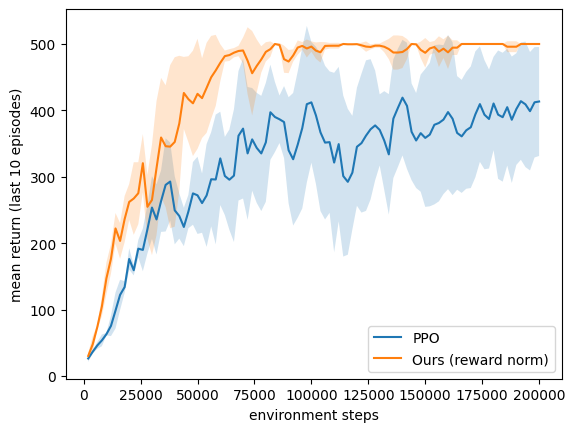

In [9]:
all_runs["Ours (reward norm)"] = run_seeds(train_fn=my_train_ppo)
mine_results = {name: summarize(all_runs[name], name) for name in ["PPO", "Ours (reward norm)"]}
import pandas as pd
print(pd.DataFrame(mine_results).T.drop(columns="name").round(1).to_string())
plot_curves({name: all_runs[name] for name in mine_results})

## Gradient norms

One seed (0), without and with reward normalization. Each line shows the gradient norm of the actor and of the critic before clipping. The clip is at `max_grad_norm = 0.5` for all parameters together.


In [10]:
print("PPO (no reward normalization)")
_ = my_train_ppo(0, verbose=True, options={"reward_norm": False})
print("\nWith reward normalization")
_ = my_train_ppo(0, verbose=True)

PPO (no reward normalization)
step  10240  mean return (last 10)   59.0  clip frac 0.000  grad norm actor 0.15 critic 39.76
step  20480  mean return (last 10)  150.5  clip frac 0.000  grad norm actor 0.19 critic 38.58
step  30720  mean return (last 10)  252.3  clip frac 0.000  grad norm actor 0.17 critic 44.17
step  40960  mean return (last 10)  243.7  clip frac 0.000  grad norm actor 0.29 critic 35.39
step  51200  mean return (last 10)  339.1  clip frac 0.000  grad norm actor 0.25 critic 31.21
step  61440  mean return (last 10)  329.3  clip frac 0.000  grad norm actor 0.30 critic 28.74
step  71680  mean return (last 10)  272.9  clip frac 0.014  grad norm actor 0.29 critic 22.60
step  81920  mean return (last 10)  278.9  clip frac 0.000  grad norm actor 0.31 critic 20.75
step  92160  mean return (last 10)  241.7  clip frac 0.000  grad norm actor 0.27 critic 22.85
step 102400  mean return (last 10)  193.3  clip frac 0.001  grad norm actor 0.29 critic 6.27
step 112640  mean return (last 

## (iv) Ablation

Removing the reward normalization gives the original PPO (`my_train_ppo(seed, options={"reward_norm": False})` is the same training as `train_ppo`), so the ablation is the PPO row of the table in (iii). The gradient norms of this variant are in the first part of the gradient norm cell above.


## (v) Analysis

5 seeds (0–4), mean ± std. The PPO row is the default PPO of Problem 3 part (a).

| Method | auc | steps_to_475 | final (greedy) | Time (s) |
|---|---|---|---|---|
| PPO | 317.5 ± 40.0 | 97,684 | 448.6 ± 78.9 | 68.8 |
| Ours (reward normalization) | 434.0 ± 12.3 | 47,425 | 500.0 ± 0.0 | 76.0 |

Per-seed `steps_to_475` (seeds 0–4): PPO 147,774 / 95,166 / 76,370 / 69,435 / 99,675; ours 46,405 / 33,484 / 62,305 / 55,938 / 38,993.

**The change improves learning.**

* The auc is 434.0 vs 317.5 (+116.5). The mean return reaches 475 in about half the steps (47.4k vs 97.7k), and it does so in fewer steps in each of the 5 seeds.
* It is also more stable: the std of the auc is 12.3 vs 40.0, and the greedy policy is 500 in all 5 seeds (PPO had 2 seeds below 475).
* The cost is about 10% more time (76.0 vs 68.8 s per run), from the running statistics and the gradient-norm logging.

**Gradient norms** before clipping in the seed-0 run (range of the values printed every 20 updates).

| | Actor | Critic |
|---|---|---|
| PPO (no normalization) | 0.13 to 0.39 | 6.3 to 44.2 |
| With reward normalization | 0.15 to 0.29 | 0.05 to 0.31 |

Without normalization, the critic gradient is much larger than the actor gradient. With normalization, both are of the same size, so the critic no longer dominates the combined gradient that PPO clips.
